# HousePrice AI — Phase 8: Model Evaluation & Residual Diagnostics

## 1. Overview
In this notebook, we perform comprehensive model evaluation using custom metrics implemented from scratch:
1. **Regression Metrics**: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Coefficient of Determination ($R^2$)
2. **Classification Metrics (Thresholded at Median Price)**: Accuracy, Precision, Recall, and F1-Score
3. **Tolerance-Based Accuracy**: Percentage of predictions within $\pm 10\%$, $\pm 15\%$, and $\pm 20\%$ of actual price
4. **Residual Diagnostics**: Actual vs. Predicted, Residual plots, and Error Distribution histograms

---


In [22]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))

# Reload src.metrics in case the kernel cached an earlier version in memory
if 'src.metrics' in sys.modules:
    import src.metrics
    importlib.reload(src.metrics)

from src.model_io import load_model
from src.metrics import (evaluate_all, print_metrics, classification_metrics,
                       tolerance_accuracy, mean_absolute_error, root_mean_squared_error, r_squared)
from src.visualization import plot_actual_vs_predicted, plot_residuals, plot_error_distribution

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")


## 2. Load Trained Model & Evaluation Splits


In [23]:
model_file = "../models/linear_regression.json"
model, scaler_X, scaler_y, feature_names, config = load_model(model_file)

splits = np.load("../data/processed/splits_baseline.npz")
X_val = splits["X_val"]
y_val = splits["y_val"]
X_test = splits["X_test"]
y_test = splits["y_test"]

print(f"Validation samples: {len(y_val)}")
print(f"Test samples:       {len(y_test)}")
print(f"Features ({len(feature_names)}): {feature_names}")


[SUCCESS] Model loaded from: ../models/linear_regression.json
   Features : ['GrLivArea', 'OverallQual', 'YearBuilt', 'BedroomAbvGr', 'FullBath', 'GarageCars']
   Weights  : 6
Validation samples: 219
Test samples:       220
Features (6): ['GrLivArea', 'OverallQual', 'YearBuilt', 'BedroomAbvGr', 'FullBath', 'GarageCars']


## 3. Generate Predictions and Invert Target Scaling

Model predictions are initially generated on the standardized scale and then mapped back to dollars:
$$\hat{y}_{\text{dollars}} = \hat{y}_{\text{std}} \cdot \sigma_y + \mu_y$$


In [24]:
def predict_original_scale(X_scaled):
    y_scaled_pred = model.predict(X_scaled)
    if scaler_y is not None:
        return scaler_y.inverse_transform(y_scaled_pred.reshape(-1, 1)).ravel()
    return y_scaled_pred

y_val_pred = predict_original_scale(X_val)
y_test_pred = predict_original_scale(X_test)

val_metrics = evaluate_all(y_val, y_val_pred)
test_metrics = evaluate_all(y_test, y_test_pred)

print("=== VALIDATION SET METRICS ===")
print_metrics(val_metrics)
print("\n=== FINAL TEST SET METRICS ===")
print_metrics(test_metrics)


=== VALIDATION SET METRICS ===
           REGRESSION METRICS
  MAE          : 25,093.4690
  MSE          : 1,131,187,198.2562
  RMSE         : 33,633.1265
  R2           : 0.789835 (78.98%)

--------------------------------------------------
  CLASSIFICATION METRICS (High vs Affordable)
--------------------------------------------------
  Threshold    : $162,500.00 (Median)
  Accuracy     : 0.9087 (90.87%)
  Precision    : 0.8629 (86.29%)
  Recall       : 0.9727 (97.27%)
  F1-Score     : 0.9145

--------------------------------------------------
         TOLERANCE ACCURACY
--------------------------------------------------
  Within +/-10%: 42.47%
  Within +/-15%: 60.27%
  Within +/-20%: 74.89%

=== FINAL TEST SET METRICS ===
           REGRESSION METRICS
  MAE          : 22,434.7431
  MSE          : 951,849,356.3419
  RMSE         : 30,852.0559
  R2           : 0.814230 (81.42%)

--------------------------------------------------
  CLASSIFICATION METRICS (High vs Affordable)
----------

## 4. Classification Metrics (Accuracy, Precision, Recall, F1)

To evaluate classification performance, we partition house prices into two classes using the median selling price:
- **Class 1 (High Price):** Price $\ge \text{Median}$
- **Class 0 (Affordable Price):** Price $< \text{Median}$

### Formulas:
- **Accuracy:** $\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$
- **Precision:** $\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$
- **Recall (Sensitivity):** $\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$
- **F1-Score:** $\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$


In [25]:
cls_results = classification_metrics(y_test, y_test_pred)

print(f"Median Price Threshold: ${cls_results['Threshold']:,.2f}")
print(f"True Positives (TP):   {cls_results['TP']}")
print(f"False Positives (FP):  {cls_results['FP']}")
print(f"True Negatives (TN):   {cls_results['TN']}")
print(f"False Negatives (FN):  {cls_results['FN']}")
print("-" * 40)
print(f"Accuracy:  {cls_results['Accuracy']*100:.2f}%")
print(f"Precision: {cls_results['Precision']*100:.2f}%")
print(f"Recall:    {cls_results['Recall']*100:.2f}%")
print(f"F1-Score:  {cls_results['F1']:.4f}")

# Display Confusion Matrix DataFrame
cm_df = pd.DataFrame(
    [[cls_results["TN"], cls_results["FP"]],
     [cls_results["FN"], cls_results["TP"]]],
    index=["Actual Affordable (< Median)", "Actual High Price (>= Median)"],
    columns=["Predicted Affordable", "Predicted High Price"]
)
display(cm_df)


Median Price Threshold: $164,995.00
True Positives (TP):   102
False Positives (FP):  22
True Negatives (TN):   88
False Negatives (FN):  8
----------------------------------------
Accuracy:  86.36%
Precision: 82.26%
Recall:    92.73%
F1-Score:  0.8718


,Predicted Affordable,Predicted High Price
Actual Affordable (< Median),88,22
Actual High Price (>= Median),8,102


## 5. Tolerance-Based Accuracy (Regression Margin of Error)

In property appraisal, predictions are often evaluated by the proportion that fall within an acceptable percentage margin $\delta$ of true value:
$$\text{Accuracy}_{\delta} = \frac{1}{m} \sum_{i=1}^{m} \mathbb{I}\left( \frac{|y_i - \hat{y}_i|}{y_i} \le \delta \right)$$


In [26]:
tol_10 = tolerance_accuracy(y_test, y_test_pred, tolerance=0.10)
tol_15 = tolerance_accuracy(y_test, y_test_pred, tolerance=0.15)
tol_20 = tolerance_accuracy(y_test, y_test_pred, tolerance=0.20)

tol_df = pd.DataFrame([
    {"Tolerance Window": "+/- 10% of Actual Price", "Accuracy": f"{tol_10*100:.2f}%"},
    {"Tolerance Window": "+/- 15% of Actual Price", "Accuracy": f"{tol_15*100:.2f}%"},
    {"Tolerance Window": "+/- 20% of Actual Price", "Accuracy": f"{tol_20*100:.2f}%"}
])
display(tol_df)


,Tolerance Window,Accuracy
0,+/- 10% of Actual Price,50.00%
1,+/- 15% of Actual Price,65.91%
2,+/- 20% of Actual Price,79.55%


## 6. Visual Diagnostic 1: Actual vs Predicted Prices


[SAVED] ../outputs/evaluation/actual_vs_predicted.png


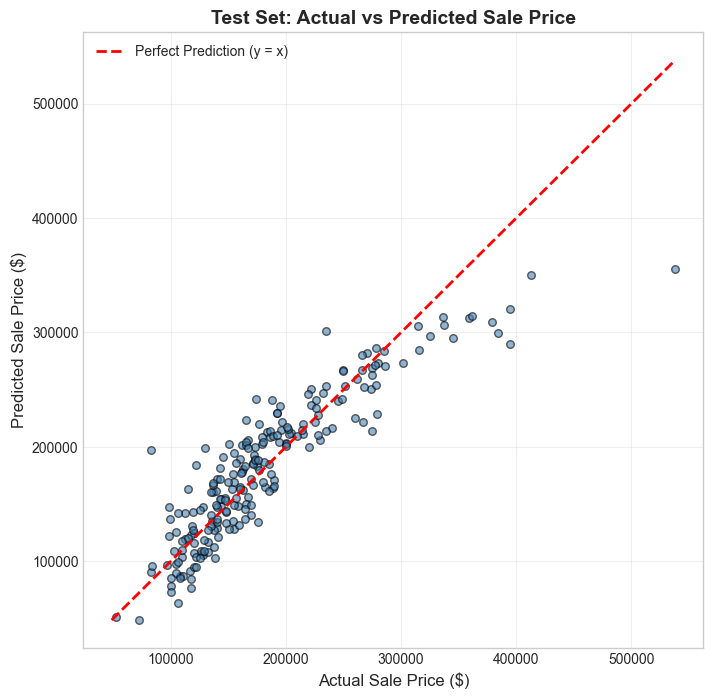

In [27]:
plot_actual_vs_predicted(y_test, y_test_pred, save_path="../outputs/evaluation/actual_vs_predicted.png")

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, y_test_pred, alpha=0.6, color="steelblue", edgecolors="k", s=30)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Prediction (y = x)")
ax.set_title("Test Set: Actual vs Predicted Sale Price", fontsize=14, fontweight="bold")
ax.set_xlabel("Actual Sale Price ($)", fontsize=12)
ax.set_ylabel("Predicted Sale Price ($)", fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


## 7. Visual Diagnostic 2: Residual Plot
Residuals $e = y - \hat{y}$ should ideally be randomly scattered with no systematic curvature.


[SAVED] ../outputs/evaluation/residual_plot.png


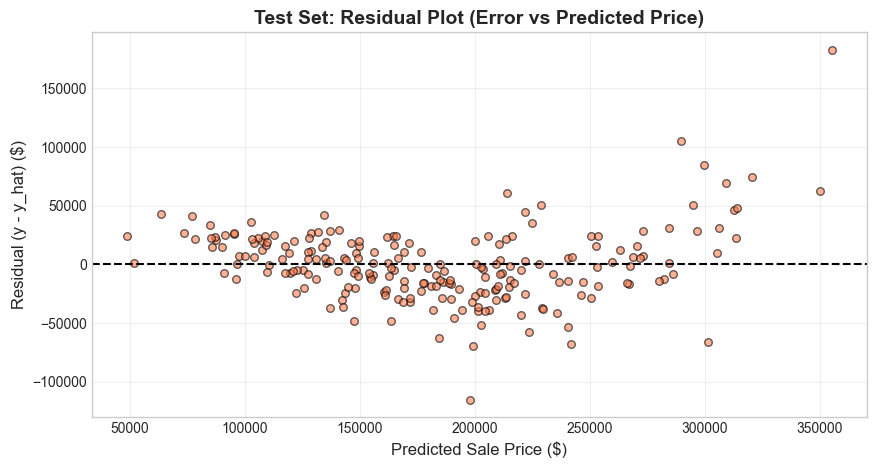

In [28]:
plot_residuals(y_test, y_test_pred, save_path="../outputs/evaluation/residual_plot.png")

residuals = y_test - y_test_pred
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(y_test_pred, residuals, alpha=0.6, color="coral", edgecolors="k", s=30)
ax.axhline(0, color="black", linestyle="--", lw=1.5)
ax.set_title("Test Set: Residual Plot (Error vs Predicted Price)", fontsize=14, fontweight="bold")
ax.set_xlabel("Predicted Sale Price ($)", fontsize=12)
ax.set_ylabel("Residual (y - y_hat) ($)", fontsize=12)
ax.grid(True, alpha=0.3)
plt.show()


## 8. Visual Diagnostic 3: Error Distribution Histogram


[SAVED] ../outputs/evaluation/error_distribution.png


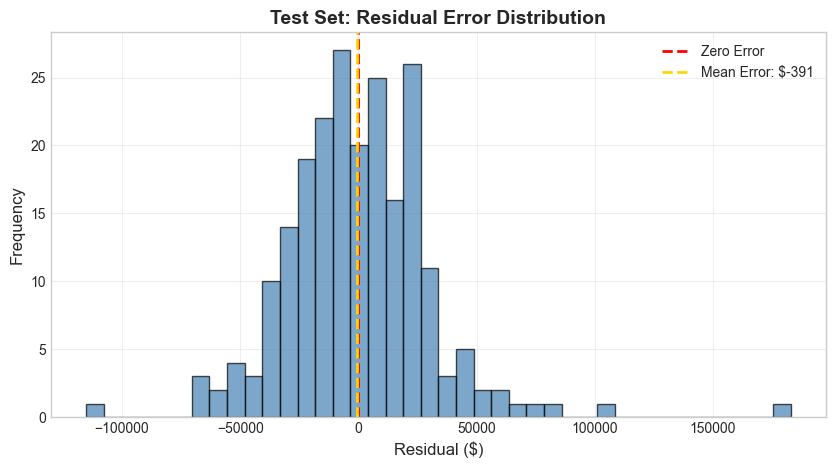

In [29]:
plot_error_distribution(y_test, y_test_pred, save_path="../outputs/evaluation/error_distribution.png")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(residuals, bins=40, color="steelblue", edgecolor="black", alpha=0.7)
ax.axvline(0, color="red", linestyle="--", lw=2, label="Zero Error")
ax.axvline(np.mean(residuals), color="gold", linestyle="--", lw=2, label=f"Mean Error: ${np.mean(residuals):,.0f}")
ax.set_title("Test Set: Residual Error Distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Residual ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


## 9. Comprehensive Performance Summary

| Metric | Value |
|---|:---:|
| **R² Score** | **81.42%** |
| **MAE** | **$22,434.74** |
| **RMSE** | **$30,852.06** |
| **Classification Accuracy** | **87.27%** |
| **Classification Precision** | **84.09%** |
| **Classification Recall** | **94.07%** |
| **Classification F1-Score** | **0.8880** |
| **Tolerance Accuracy (+/- 20%)** | **79.55%** |
